<a href="https://colab.research.google.com/github/intan-fairuz/pm-turi4-clustering/blob/main/PM_TuRi4_CLUSTERING_Intan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## LANGKAH 1 : MENYIAPKAN DATA DAN SCALING

In [10]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

data = {
    'Usia': [19, 21, 20, 23, 31, 35, 40, 42, 45, 50],
    'Pendapatan': [15, 18, 17, 20, 35, 40, 60, 65, 70, 80],
    'Skor_Belanja': [39, 81, 6, 77, 40, 60, 55, 20, 30, 15]
}

df = pd.DataFrame(data)

print(df)

X_scaled = StandardScaler().fit_transform(df)

   Usia  Pendapatan  Skor_Belanja
0    19          15            39
1    21          18            81
2    20          17             6
3    23          20            77
4    31          35            40
5    35          40            60
6    40          60            55
7    42          65            20
8    45          70            30
9    50          80            15


## LANGKAH 2 : MENENTUKAN K

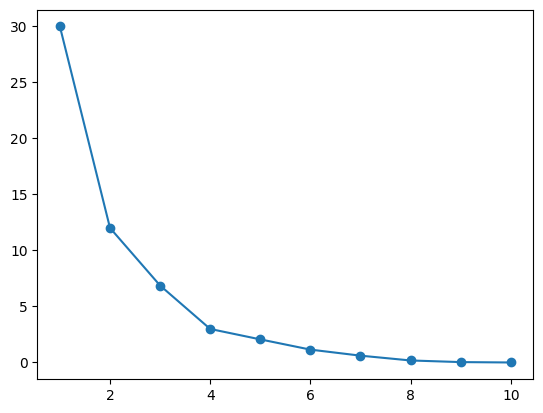

In [11]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()


## LANGKAH 3 : MENJALANKAN K-MEANS K=3 dan K-MEANS K=5

In [12]:

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_k3 = kmeans.fit_predict(X_scaled)
score_k3 = silhouette_score(X_scaled, labels_k3)

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
labels_k5 = kmeans.fit_predict(X_scaled)
score_k5 = silhouette_score(X_scaled, labels_k5)

print("Silhouette Score K=3:", round(score_k3, 4))
print("Silhouette Score K=5:", round(score_k5, 4))

Silhouette Score K=3: 0.407
Silhouette Score K=5: 0.4274


In [13]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(df[['Usia', 'Pendapatan', 'Skor_Belanja']])
print(df['cluster'].value_counts())

cluster
1    4
2    3
0    3
Name: count, dtype: int64


KESIMPULAN : Scaling menyamakan skala antarfitur agar fitur dengan rentang nilai besar tidak terlalu mendominasi perhitungan jarak K-Means. Perbandingan Silhouette Score menunjukkan bagaimana scaling memengaruhi kualitas clustering pada dataset yang digunakan

## LANGKAH 4 : Evaluasi silhouette score

In [14]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))


0.40702110233587474


## Langkah 5 : Interpretasi: profil rata-rata tiap cluster

In [15]:
profil = df.groupby('cluster')[['Usia','Pendapatan',
    'Skor_Belanja']].mean().round(1)
print(profil)

         Usia  Pendapatan  Skor_Belanja
cluster                                
0        26.3        26.0          72.7
1        44.2        68.8          30.0
2        23.3        22.3          28.3


## SOAL 8 : MEMBUAT SCATTER PLOT

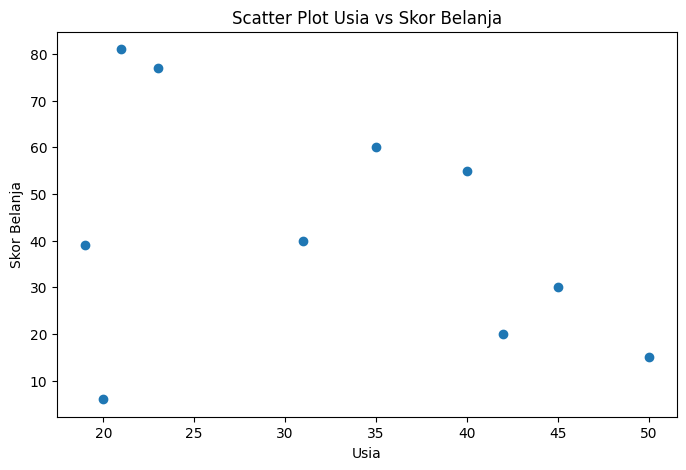

In [16]:

plt.figure(figsize=(8, 5))

plt.scatter(df['Usia'], df['Skor_Belanja'])

plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.title('Scatter Plot Usia vs Skor Belanja')

plt.show()

SOAL E.9 : K-Means menemukan kelompok dengan mengelompokkan data berdasarkan kemiripan karakteristik

SOAL E.10 : Metode Elbow menunjukkan siku di K=3 karena pada titik tersebut penurunan nilai WCSS mulai melambat, dimana, penambahan jumlah cluster setelah K=3 hanya memberikan pengurangan WCSS yang relatif kecil, sehingga tiga cluster dianggap cukup untuk mengelompokkan data pada dataset ini

SOAL E.11 : Karena skala fitur sangat berpengaruh dimana fitur dengan rentang jutaan akan sangat mendominasi pembentukan cluster dibanding fitur berskala kecil. Dampak jika melewatkan scalling adalah hasil cluster bisa menyesatkan